# 06 — Safety-oriented model tuning

Tune LightGBM, Random Forest, and Decision Tree using only the saved 4,000-row training split. Nested cross-validation separates inner hyperparameter/threshold selection from outer-fold evaluation; the held-out test partition remains untouched.

The positive class is poisonous (1). A false negative means poisonous predicted edible and is prioritized over a false positive. Recall is considered alongside precision and balanced accuracy so a model that labels almost everything poisonous is not treated as useful. All results are educational—not real-world mushroom-safety guidance.

## 1. Introduction and objectives

Compare each original candidate, its randomized-search tuned version at the default threshold, and its tuned version using a safety-oriented threshold. Search and threshold selection happen only within outer-training partitions. This notebook does not use or load the test split.

## 2. Imports and configuration

In [1]:
# Check LightGBM before importing so a missing optional model fails with an actionable message.
from importlib.util import find_spec
from pathlib import Path
import json
import sys
import time

# Libraries for experiment tracking, nested CV, plots, and saving the final training-only candidate.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import dump
# clone creates fresh estimators for every outer and inner fold.
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    balanced_accuracy_score,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn import __version__ as sklearn_version

if find_spec('lightgbm') is None:
    raise ModuleNotFoundError(
        'LightGBM is required for this comparison but is not installed. '
        'Install it in the active environment with: pip install lightgbm'
    )
from lightgbm import LGBMClassifier, __version__ as lightgbm_version

# Locate the repository root without assuming where the notebook kernel was started.
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'mushroom' / 'preprocessing.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate mushroom/preprocessing.py from the notebook directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Use the shared preprocessing recipe inside every estimator pipeline.
from mushroom.preprocessing import build_preprocessor

# Store all generated tables, figures, and candidate models in the project data directory.
DATA_DIR = PROJECT_ROOT / 'mushroom' / 'data'
FIGURE_DIR = DATA_DIR / 'figures'
MODEL_DIR = DATA_DIR / 'models'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Nested cross-validation settings: outer folds estimate generalization, inner folds tune.
RANDOM_STATE = 42
OUTER_SPLITS = 5
INNER_SPLITS = 3
N_ITER = 20
POSITIVE_LABEL = 1
# Guardrails prevent recall maximization from accepting a useless all-positive classifier.
MIN_BALANCED_ACCURACY = 0.65
MIN_POISONOUS_PRECISION = 0.50
# Candidate thresholds are evaluated using inner-CV predictions only.
THRESHOLDS = np.array([0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50])
# Keep poisonous class 1 explicit for every safety-oriented classification metric.
SCORING = {
    'poisonous_recall': make_scorer(recall_score, pos_label=1, zero_division=0),
    'balanced_accuracy': 'balanced_accuracy',
    'poisonous_precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'poisonous_f1': make_scorer(f1_score, pos_label=1, zero_division=0),
    'roc_auc': 'roc_auc',
}
plt.style.use('seaborn-v0_8-whitegrid')
print(f'Project: {PROJECT_ROOT}')
print(f'scikit-learn={sklearn_version}; LightGBM={lightgbm_version}')
print(f'Nested CV: {OUTER_SPLITS} outer folds, {INNER_SPLITS} inner folds, {N_ITER} randomized configurations/model/fold')

Project: /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5
scikit-learn=1.4.2; LightGBM=4.7.0
Nested CV: 5 outer folds, 3 inner folds, 20 randomized configurations/model/fold


## 3. Load and validate training data

Read only the saved raw training features and target. Metadata supplies the established numerical and categorical feature groups for the shared preprocessor. No test data is opened.

In [2]:
# Read metadata and raw training features/labels only. The held-out test partition
# is intentionally not loaded anywhere in this tuning notebook.
# The metadata is created by notebook 02 and is the source of truth for feature types.
with (DATA_DIR / 'mushroom_preprocessing_metadata.json').open(encoding='utf-8') as file:
    preprocessing_metadata = json.load(file)
# Load the untouched feature columns and the matching binary target as separate artifacts.
X_train = pd.read_parquet(DATA_DIR / 'mushroom_X_train_raw.parquet')
y_frame = pd.read_parquet(DATA_DIR / 'mushroom_y_train.parquet')
# Verify target layout, feature order, row count, and the required edible/poisonous mapping.
if y_frame.shape[1] != 1:
    raise ValueError(f'Expected exactly one target column, got {y_frame.shape[1]}.')
y_train = y_frame.iloc[:, 0].rename('class')
# Reuse the recorded numerical/categorical schema when constructing every pipeline.
numeric_cols = preprocessing_metadata['numerical_features']
categorical_cols = preprocessing_metadata['categorical_features']
# Fail early if the parquet files and metadata no longer describe the same feature matrix.
if X_train.columns.tolist() != numeric_cols + categorical_cols:
    raise ValueError('Feature columns/order differ from preprocessing metadata.')
if len(X_train) != len(y_train) or len(X_train) != 4000:
    raise ValueError(f'Expected 4,000 matching training observations; got {len(X_train)} and {len(y_train)}.')
if set(y_train.unique()) != {0, 1} or preprocessing_metadata['target_mapping'] != {'e': 0, 'p': 1}:
    raise ValueError('Target labels/mapping must remain 0=edible and 1=poisonous.')
# Inspect training feature types and missingness without fitting any transformations.
# Show the amount of missingness by feature; imputation happens later inside CV pipelines.
display(pd.DataFrame({
    'dtype': X_train.dtypes.astype(str),
    'missing': X_train.isna().sum(),
    'missing_percent': (100 * X_train.isna().mean()).round(2),
}))
# Show class counts with human-readable names while leaving the encoded target unchanged.
display(y_train.value_counts().sort_index().rename(index={0: 'Edible (0)', 1: 'Poisonous (1)'}).to_frame('count'))
print(f'Validated {X_train.shape[0]} rows and {X_train.shape[1]} features; total missing feature values={X_train.isna().sum().sum():,}.')

,dtype,missing,missing_percent
cap-diameter,float64,1591,39.78
stem-height,float64,820,20.50
stem-width,float64,308,7.70
spore-print-color,str,3797,94.92
gill-color,str,776,19.40
habitat,str,809,20.23
season,str,776,19.40
ring-type,str,453,11.32
cap-shape,str,323,8.08
stem-surface,str,2700,67.50


,count
class,
Edible (0),2486
Poisonous (1),1514


Validated 4000 rows and 10 features; total missing feature values=12,353.


## 4. Define models and parameter distributions

Each estimator is inside a Pipeline with a fresh shared preprocessor. Randomized search fits that complete pipeline independently on each inner training fold. Search spaces include unweighted, balanced, and explicitly poisonous-upweighted class weights.

In [3]:
# Every candidate is a complete preprocessing-plus-classifier pipeline, so each fold
# learns imputation and encoding only from its own training observations.
# A new unfitted transformer is made for each candidate pipeline.
def make_pipeline(classifier):
    return Pipeline([
        ('preprocessor', build_preprocessor(numeric_cols, categorical_cols)),
        ('classifier', classifier),
    ])

# Explore increasing poisonous-class penalties during tuning; these are candidates, not defaults.
class_weights = [None, 'balanced', {0: 1, 1: 2}, {0: 1, 1: 3}]
# Create one baseline pipeline per algorithm; all use the same random seed where supported.
pipelines = {
    'LightGBM': make_pipeline(LGBMClassifier(
        random_state=RANDOM_STATE, verbosity=-1, n_jobs=1
    )),
    'Random Forest': make_pipeline(RandomForestClassifier(
        random_state=RANDOM_STATE, n_jobs=1
    )),
    'Decision Tree': make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
}
# Search spaces are deliberately model-specific and remain bounded for practical runtime.
# Keys use the sklearn Pipeline step name 'classifier' followed by estimator parameters.
# RandomizedSearchCV samples from these options inside the inner CV loop.
parameter_distributions = {
    'LightGBM': {
        'classifier__n_estimators': [100, 200, 350],
        'classifier__learning_rate': [0.03, 0.05, 0.10],
        'classifier__num_leaves': [15, 31, 63],
        'classifier__max_depth': [-1, 5, 10, 15],
        'classifier__min_child_samples': [10, 20, 40, 60],
        'classifier__subsample': [0.70, 0.85, 1.0],
        'classifier__subsample_freq': [0, 1],
        'classifier__colsample_bytree': [0.70, 0.85, 1.0],
        'classifier__reg_lambda': [0.0, 0.1, 1.0, 5.0],
        'classifier__class_weight': class_weights,
    },
    'Random Forest': {
        'classifier__n_estimators': [150, 250, 400],
        'classifier__max_depth': [None, 10, 20, 30],
        'classifier__min_samples_split': [2, 5, 10],
        'classifier__min_samples_leaf': [1, 2, 4],
        'classifier__max_features': ['sqrt', 0.5, None],
        'classifier__class_weight': class_weights,
    },
    'Decision Tree': {
        'classifier__max_depth': [None, 5, 10, 20, 30],
        'classifier__min_samples_split': [2, 5, 10, 20],
        'classifier__min_samples_leaf': [1, 2, 4, 8],
        'classifier__max_features': [None, 'sqrt', 0.5],
        'classifier__class_weight': class_weights,
        'classifier__ccp_alpha': [0.0, 0.0001, 0.001, 0.005],
    },
}
# Report exactly which model families are included in the nested comparison.
print('Models:', list(pipelines))
print('All estimators use random_state=42 and n_jobs=1; no SMOTE or threshold changes are applied here.')

Models: ['LightGBM', 'Random Forest', 'Decision Tree']
All estimators use random_state=42 and n_jobs=1; no SMOTE or threshold changes are applied here.


## 5. Define safety-oriented scoring and selection rules

Inner randomized search selects the candidate with the highest mean poisonous recall among configurations that also achieve at least 0.65 balanced accuracy and 0.50 poisonous precision at the default 0.5 threshold. These are exploratory guardrails, not validated safety thresholds. If none pass, the highest-recall candidate is retained for analysis and the failed constraint is explicitly recorded; constraints are never silently relaxed.

After hyperparameter selection, choose a threshold from inner out-of-fold probabilities. Among thresholds meeting the same guardrails, prefer highest recall, then F1 and balanced accuracy. If none qualify, report that and use the highest-recall threshold only as a flagged exploratory fallback. Outer-fold labels never affect either selection.

In [4]:
# Choose one inner-CV parameter set using guardrails first, then a lexicographic
# objective that prioritizes poisonous recall and uses other metrics as tie-breakers.
# The returned integer is the index of the chosen candidate in cv_results arrays.
def select_search_candidate(cv_results):
    # Convert metric columns into NumPy arrays for vectorized feasibility checks and ranking.
    recall_values = np.asarray(cv_results['mean_test_poisonous_recall'])
    precision_values = np.asarray(cv_results['mean_test_poisonous_precision'])
    balanced_values = np.asarray(cv_results['mean_test_balanced_accuracy'])
    f1_values = np.asarray(cv_results['mean_test_poisonous_f1'])
    auc_values = np.asarray(cv_results['mean_test_roc_auc'])
    # A feasible candidate meets both minimum utility constraints at the default threshold.
    feasible = (
        (precision_values >= MIN_POISONOUS_PRECISION)
        & (balanced_values >= MIN_BALANCED_ACCURACY)
    )
    # If nothing qualifies, choose from all candidates but the caller reports that fallback.
    candidates = np.flatnonzero(feasible) if feasible.any() else np.arange(len(recall_values))
    # np.lexsort uses the final key as primary: recall, then F1, balanced accuracy, then AUC.
    return int(candidates[np.lexsort((
        auc_values[candidates],
        balanced_values[candidates],
        f1_values[candidates],
        recall_values[candidates],
    ))[-1]])

# Convert predicted probabilities at a threshold into metrics and confusion counts.
# Label 1 is poisonous; a false negative means poisonous predicted edible.
# This helper is used for inner threshold sweeps and diagnostic threshold plots.
def threshold_metrics(y_true, positive_probability, threshold):
    # Match sklearn's strict probability comparison, including ties at exactly 0.5.
    y_pred = (positive_probability > threshold).astype(int)
    # Fix label order so the flattened matrix is always TN, FP, FN, TP.
    tn, fp, fn, tp = __import__('sklearn.metrics', fromlist=['confusion_matrix']).confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    # Return scalar metrics and raw counts so tables can report both rates and actual errors.
    return {
        'poisonous_recall': float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'false_negatives': int(fn),
        'false_negative_rate': float(fn / (fn + tp)) if fn + tp else float('nan'),
        'poisonous_precision': float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'poisonous_f1': float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'false_positives': int(fp),
        'true_negatives': int(tn),
        'true_positives': int(tp),
        'predictions': y_pred,
    }

# Select a threshold from the inner OOF probability sweep, subject to the same guardrails.
# If none qualify, retain a flagged fallback rather than silently changing constraints.
# The boolean return value records whether any threshold met both minimum requirements.
def choose_threshold(y_true, probabilities):
    rows = []
    for threshold in THRESHOLDS:
        metrics = threshold_metrics(y_true, probabilities, float(threshold))
        rows.append({'threshold': float(threshold), **metrics})
    # Keep thresholds with adequate balanced accuracy and poisonous precision when possible.
    eligible = [
        row for row in rows
        if row['balanced_accuracy'] >= MIN_BALANCED_ACCURACY
        and row['poisonous_precision'] >= MIN_POISONOUS_PRECISION
    ]
    # The fallback pool is explicit and is surfaced to the caller as not feasible.
    pool = eligible if eligible else rows
    # Prefer recall, then F1, balanced accuracy, precision; if still tied prefer lower threshold.
    selected = max(
        pool,
        key=lambda row: (
            row['poisonous_recall'],
            row['poisonous_f1'],
            row['balanced_accuracy'],
            row['poisonous_precision'],
            -row['threshold'],
        ),
    )
    # Preserve every threshold's metrics so the selected choice can be audited later.
    return selected, pd.DataFrame(rows), bool(eligible)

# Calculate consistent metric and error-count summaries for any held-out predictions.
# Probability scores are used for AUC; thresholded labels are used for classification rates.
def evaluate_at_predictions(y_true, y_pred, probabilities):
    tn, fp, fn, tp = __import__('sklearn.metrics', fromlist=['confusion_matrix']).confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    # Return metrics and confusion-matrix counts with the same label convention as threshold_metrics.
    return {
        'accuracy': float(np.mean(np.asarray(y_true) == np.asarray(y_pred))),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'poisonous_precision': float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'poisonous_recall': float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'poisonous_f1': float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_true, probabilities)),
        'false_negatives': int(fn),
        'false_negative_rate': float(fn / (fn + tp)) if fn + tp else float('nan'),
        'false_positives': int(fp),
        'true_negatives': int(tn),
        'true_positives': int(tp),
    }

# Save training-versus-validation metric gaps as overfitting diagnostics, not as
# estimates of generalization from training scores.
# The caller supplies predictions for the fit partition and its held-out validation partition.
def append_fit_gap(gap_rows, model_name, strategy, fold, y_fit, fit_prediction,
                   fit_probability, y_valid, valid_prediction, valid_probability):
    # Compute both metric dictionaries using the same helper to keep the gap definition consistent.
    fit_metrics = evaluate_at_predictions(y_fit, fit_prediction, fit_probability)
    valid_metrics = evaluate_at_predictions(y_valid, valid_prediction, valid_probability)
    # Track the safety-oriented recall and the complementary balanced/AUC scores.
    for metric in ['poisonous_recall', 'balanced_accuracy', 'roc_auc']:
        gap_rows.append({
            'model': model_name,
            'strategy': strategy,
            'outer_fold': fold,
            'metric': metric,
            'outer_training_score_in_sample': fit_metrics[metric],
            'outer_validation_score': valid_metrics[metric],
            'train_minus_validation': fit_metrics[metric] - valid_metrics[metric],
        })

# Convert NumPy scalar/container values into native Python values before JSON output.
# This handles nested search parameter dictionaries without silently stringifying values.
def json_safe(value):
    # NumPy scalar wrappers (for example np.int64) are not JSON serializable by default.
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    return value

print(f'Inner search refit guardrails: balanced accuracy >= {MIN_BALANCED_ACCURACY:.2f}, poisonous precision >= {MIN_POISONOUS_PRECISION:.2f}.')
print('Threshold comparisons use positive_probability > threshold, matching sklearn predict behavior at exact 0.5 ties.')

Inner search refit guardrails: balanced accuracy >= 0.65, poisonous precision >= 0.50.
Threshold comparisons use positive_probability > threshold, matching sklearn predict behavior at exact 0.5 ties.


## 6. Nested cross-validation

The same five stratified outer folds are used for every model. In each outer fold, randomized search (3-fold inner CV) and threshold selection use only the outer training rows. Only after both choices are fixed is the selected estimator evaluated on the untouched outer validation fold. Original default models are evaluated on the same outer folds for paired comparisons.

In [5]:
# This cell performs nested CV: every outer validation fold stays untouched while
# randomized search and threshold selection use only that outer fold's training rows.
# Each outer validation row will later contribute one held-out prediction per model/strategy.
outer_cv = StratifiedKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=RANDOM_STATE)
outer_folds = list(outer_cv.split(X_train, y_train))
# Keep strategy labels stable because they are used as keys in prediction/metric tables.
strategy_names = ['Untuned (threshold 0.5)', 'Tuned (threshold 0.5)', 'Tuned (inner-CV threshold)']
# Lists collect fold-level records; arrays hold each row's held-out class/probability.
outer_records = []
search_records = []
threshold_records = []
outer_fit_gap_records = []
# Initialize one slot per training row; each row is filled exactly once as outer validation data.
outer_predictions = {
    model_name: {strategy: np.full(len(y_train), -1, dtype=int) for strategy in strategy_names}
    for model_name in pipelines
}
# NaN marks a probability that has not yet been populated by an outer validation fold.
outer_probabilities = {
    model_name: {strategy: np.full(len(y_train), np.nan, dtype=float) for strategy in strategy_names}
    for model_name in pipelines
}
# Keep probabilities for a later threshold diagnostic; this sweep is not used for selection.
threshold_sweep_probabilities = {model_name: np.full(len(y_train), np.nan) for model_name in pipelines}
search_runtimes = {model_name: [] for model_name in pipelines}
nested_started = time.perf_counter()

# Iterate outer folds and isolate each outer-training/outer-validation partition.
for outer_fold_number, (outer_train_indices, outer_valid_indices) in enumerate(outer_folds, start=1):
    # Select rows by positional fold indices to preserve the exact precomputed CV partition.
    X_outer_train = X_train.iloc[outer_train_indices]
    y_outer_train = y_train.iloc[outer_train_indices]
    X_outer_valid = X_train.iloc[outer_valid_indices]
    y_outer_valid = y_train.iloc[outer_valid_indices]
    # Use a fold-specific deterministic seed while preserving stratification in inner CV.
    inner_cv = StratifiedKFold(
        n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE + outer_fold_number
    )
    # Materialize inner folds once so search and OOF threshold selection share them.
    inner_folds = list(inner_cv.split(X_outer_train, y_outer_train))
    print(f'Outer fold {outer_fold_number}/{OUTER_SPLITS}: train={len(outer_train_indices)}, validation={len(outer_valid_indices)}')

    # Compare each model's untuned default, tuned default threshold, and tuned inner-CV threshold.
    for model_name, pipeline in pipelines.items():
        # Original default candidate, evaluated on this same held-out outer fold.
        untuned = clone(pipeline).fit(X_outer_train, y_outer_train)
        # Keep probabilities for AUC and later diagnostics; column 1 corresponds to poisonous.
        untuned_probability = untuned.predict_proba(X_outer_valid)[:, 1]
        untuned_prediction = untuned.predict(X_outer_valid)
        # Record in-sample versus held-out metrics to inspect possible overfitting.
        append_fit_gap(
            outer_fit_gap_records, model_name, strategy_names[0], outer_fold_number,
            y_outer_train, untuned.predict(X_outer_train), untuned.predict_proba(X_outer_train)[:, 1],
            y_outer_valid, untuned_prediction, untuned_probability,
        )
        outer_predictions[model_name][strategy_names[0]][outer_valid_indices] = untuned_prediction
        outer_probabilities[model_name][strategy_names[0]][outer_valid_indices] = untuned_probability
        # Save a separate record with this fold's test-like outer validation metrics.
        outer_records.append({
            'model': model_name,
            'strategy': strategy_names[0],
            'outer_fold': outer_fold_number,
            'threshold': 0.5,
            **evaluate_at_predictions(y_outer_valid, untuned_prediction, untuned_probability),
        })

        # Search hyperparameters inside only the outer-training subset; outer validation
        # data cannot affect parameter selection or its preprocessing.
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=parameter_distributions[model_name],
            n_iter=N_ITER,
            scoring=SCORING,
            refit=select_search_candidate,
            cv=inner_folds,
            random_state=RANDOM_STATE + outer_fold_number,
            n_jobs=1,
            return_train_score=True,
            error_score='raise',
            verbose=0,
        )
        search_started = time.perf_counter()
        search.fit(X_outer_train, y_outer_train)
        elapsed = time.perf_counter() - search_started
        search_runtimes[model_name].append(elapsed)

        # best_index points to the candidate chosen by select_search_candidate, not a single metric.
        best_index = search.best_index_
        cv_results = search.cv_results_
        inner_feasible = (
            cv_results['mean_test_balanced_accuracy'][best_index] >= MIN_BALANCED_ACCURACY
            and cv_results['mean_test_poisonous_precision'][best_index] >= MIN_POISONOUS_PRECISION
        )
        feasible_count = int(np.sum(
            (np.asarray(cv_results['mean_test_balanced_accuracy']) >= MIN_BALANCED_ACCURACY)
            & (np.asarray(cv_results['mean_test_poisonous_precision']) >= MIN_POISONOUS_PRECISION)
        ))
        # Store inner performance and train/validation gaps to make the selection auditable.
        search_records.append({
            'model': model_name,
            'outer_fold': outer_fold_number,
            'inner_feasible_configurations': feasible_count,
            'selected_configuration_feasible_at_0_5': bool(inner_feasible),
            'best_inner_recall': float(cv_results['mean_test_poisonous_recall'][best_index]),
            'best_inner_precision': float(cv_results['mean_test_poisonous_precision'][best_index]),
            'best_inner_balanced_accuracy': float(cv_results['mean_test_balanced_accuracy'][best_index]),
            'best_inner_f1': float(cv_results['mean_test_poisonous_f1'][best_index]),
            'best_inner_roc_auc': float(cv_results['mean_test_roc_auc'][best_index]),
            'inner_train_recall': float(cv_results['mean_train_poisonous_recall'][best_index]),
            'inner_train_balanced_accuracy': float(cv_results['mean_train_balanced_accuracy'][best_index]),
            'inner_train_roc_auc': float(cv_results['mean_train_roc_auc'][best_index]),
            'search_seconds': float(elapsed),
            'best_params': json.dumps(json_safe(search.best_params_), sort_keys=True),
        })
        # Surface both no-feasible-candidate and selected-infeasible fallback cases immediately.
        if not feasible_count:
            print(f'  NOTE {model_name}, fold {outer_fold_number}: no inner-search configuration met both guardrails; the fallback is explicitly flagged.')
        elif not inner_feasible:
            print(f'  NOTE {model_name}, fold {outer_fold_number}: selected recall-max configuration fell outside the guardrails; see search table.')

        # Apply the selected inner-CV parameter configuration to the untouched outer fold.
        tuned_estimator = search.best_estimator_
        # First assess the tuned estimator with its default decision threshold of 0.5.
        tuned_probability = tuned_estimator.predict_proba(X_outer_valid)[:, 1]
        tuned_default_prediction = tuned_estimator.predict(X_outer_valid)
        outer_predictions[model_name][strategy_names[1]][outer_valid_indices] = tuned_default_prediction
        outer_probabilities[model_name][strategy_names[1]][outer_valid_indices] = tuned_probability
        outer_records.append({
            'model': model_name,
            'strategy': strategy_names[1],
            'outer_fold': outer_fold_number,
            'threshold': 0.5,
            **evaluate_at_predictions(y_outer_valid, tuned_default_prediction, tuned_probability),
        })

        # Generate inner OOF probabilities for threshold selection without using outer validation.
        inner_oof_probability = cross_val_predict(
            clone(tuned_estimator),
            X_outer_train,
            y_outer_train,
            cv=inner_folds,
            method='predict_proba',
            n_jobs=1,
        )[:, 1]
        # Select the threshold using only inner OOF predictions; evaluate it afterward on outer data.
        selected_threshold, fold_threshold_table, threshold_feasible = choose_threshold(
            y_outer_train, inner_oof_probability
        )
        # Preserve all inner threshold results, not only the selected threshold.
        for _, threshold_row in fold_threshold_table.iterrows():
            threshold_records.append({
                'model': model_name,
                'outer_fold': outer_fold_number,
                'threshold': threshold_row['threshold'],
                'inner_recall': threshold_row['poisonous_recall'],
                'inner_precision': threshold_row['poisonous_precision'],
                'inner_f1': threshold_row['poisonous_f1'],
                'inner_balanced_accuracy': threshold_row['balanced_accuracy'],
                'inner_false_negatives': threshold_row['false_negatives'],
                'inner_false_negative_rate': threshold_row['false_negative_rate'],
                'threshold_met_guardrails': bool(
                    threshold_row['poisonous_precision'] >= MIN_POISONOUS_PRECISION
                    and threshold_row['balanced_accuracy'] >= MIN_BALANCED_ACCURACY
                ),
                'selected_in_inner_cv': bool(threshold_row['threshold'] == selected_threshold['threshold']),
            })
        if not threshold_feasible:
            print(f'  NOTE {model_name}, fold {outer_fold_number}: no inner-CV threshold met both guardrails; selected threshold is a flagged fallback.')
        # Apply the inner-selected threshold to outer probabilities only after selection is finished.
        outer_threshold_prediction = (tuned_probability > selected_threshold['threshold']).astype(int)
        tuned_train_probability = tuned_estimator.predict_proba(X_outer_train)[:, 1]
        tuned_train_prediction = tuned_estimator.predict(X_outer_train)
        append_fit_gap(
            outer_fit_gap_records, model_name, strategy_names[1], outer_fold_number,
            y_outer_train, tuned_train_prediction, tuned_train_probability,
            y_outer_valid, tuned_default_prediction, tuned_probability,
        )
        append_fit_gap(
            outer_fit_gap_records, model_name, strategy_names[2], outer_fold_number,
            y_outer_train, (tuned_train_probability > selected_threshold['threshold']).astype(int),
            tuned_train_probability, y_outer_valid, outer_threshold_prediction, tuned_probability,
        )
        # Fill the tuned-threshold OOF slots for these outer validation rows.
        outer_predictions[model_name][strategy_names[2]][outer_valid_indices] = outer_threshold_prediction
        outer_probabilities[model_name][strategy_names[2]][outer_valid_indices] = tuned_probability
        threshold_sweep_probabilities[model_name][outer_valid_indices] = tuned_probability
        # This is the unbiased outer-fold evaluation of the inner-selected threshold.
        outer_records.append({
            'model': model_name,
            'strategy': strategy_names[2],
            'outer_fold': outer_fold_number,
            'threshold': selected_threshold['threshold'],
            'threshold_met_inner_guardrails': threshold_feasible,
            **evaluate_at_predictions(y_outer_valid, outer_threshold_prediction, tuned_probability),
        })
        print(
            f'  {model_name}: selected threshold={selected_threshold["threshold"]:.2f} '
            f'(inner recall={selected_threshold["poisonous_recall"]:.3f}, '
            f'precision={selected_threshold["poisonous_precision"]:.3f}, '
            f'balanced accuracy={selected_threshold["balanced_accuracy"]:.3f}); '
            f'search={elapsed:.1f}s'
        )

# Convert accumulated fold records to tables for analysis and persistence in later sections.
nested_runtime_seconds = time.perf_counter() - nested_started
outer_df = pd.DataFrame(outer_records)
search_df = pd.DataFrame(search_records)
threshold_df = pd.DataFrame(threshold_records)
print(f'Nested evaluation completed in {nested_runtime_seconds / 60:.1f} minutes.')

Outer fold 1/5: train=3200, validation=800
  LightGBM: selected threshold=0.50 (inner recall=0.791, precision=0.519, balanced accuracy=0.672); search=14.1s
  Random Forest: selected threshold=0.40 (inner recall=0.847, precision=0.528, balanced accuracy=0.693); search=82.4s
  Decision Tree: selected threshold=0.40 (inner recall=0.707, precision=0.525, balanced accuracy=0.659); search=2.7s
Outer fold 2/5: train=3200, validation=800
  LightGBM: selected threshold=0.45 (inner recall=0.826, precision=0.501, balanced accuracy=0.662); search=12.1s
  Random Forest: selected threshold=0.50 (inner recall=0.856, precision=0.501, balanced accuracy=0.669); search=88.1s
  Decision Tree: selected threshold=0.25 (inner recall=0.683, precision=0.565, balanced accuracy=0.682); search=2.7s
Outer fold 3/5: train=3200, validation=800
  LightGBM: selected threshold=0.50 (inner recall=0.771, precision=0.530, balanced accuracy=0.677); search=15.2s
  Random Forest: selected threshold=0.50 (inner recall=0.815, 

## 7. Hyperparameter search results

The table reports the inner-CV metrics for the selected configuration within each outer training fold. These are optimization diagnostics, not unbiased performance estimates. Outer-fold scores are reported separately below. A zero feasible count means the stated default-threshold guardrails were not met by any sampled configuration in that inner search.

In [6]:
# Show per-outer-fold search choices and feasibility flags before summarizing them.
# Inner scores explain selection behavior; they are not estimates of final model performance.
display(search_df[[
    'model', 'outer_fold', 'inner_feasible_configurations',
    'selected_configuration_feasible_at_0_5', 'best_inner_recall',
    'best_inner_precision', 'best_inner_balanced_accuracy', 'best_inner_f1',
    'best_inner_roc_auc', 'inner_train_recall', 'inner_train_balanced_accuracy',
    'inner_train_roc_auc', 'search_seconds', 'best_params',
]])
# Keep the detailed configurations available as a separate CSV for reproducibility.
search_df.to_csv(DATA_DIR / 'mushroom_tuning_search_results.csv', index=False)

# Summarize how selected inner-CV recall varied across outer-training partitions.
fig, ax = plt.subplots(figsize=(10, 5))
# The error bars are standard deviations across outer folds, not confidence intervals.
search_means = search_df.groupby('model')['best_inner_recall'].agg(['mean', 'std']).reindex(pipelines)
ax.bar(search_means.index, search_means['mean'], yerr=search_means['std'], capsize=4)
ax.set(ylim=(0, 1), ylabel='Selected inner-CV poisonous recall', title='Search-selected inner-CV recall by outer training fold')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_tuning_inner_search_recall.png', dpi=160)
# Display the saved inner-search chart once, then close to suppress duplicate inline output.
plt.show()
plt.close(fig)
print('Search-selected inner scores are not presented as final generalization estimates.')

,model,outer_fold,inner_feasible_configurations,selected_configuration_feasible_at_0_5,best_inner_recall,best_inner_precision,best_inner_balanced_accuracy,best_inner_f1,best_inner_roc_auc,inner_train_recall,inner_train_balanced_accuracy,inner_train_roc_auc,search_seconds,best_params
0,LightGBM,1,17,True,0.791254,0.518826,0.671788,0.626556,0.763165,0.941832,0.810453,0.923766,14.111674,"{""classifier__class_weight"": {""0"": 1, ""1"": 3},..."
1,Random Forest,1,18,True,0.712871,0.623288,0.724903,0.664747,0.793409,0.971122,0.934502,0.982273,82.433533,"{""classifier__class_weight"": {""0"": 1, ""1"": 3},..."
2,Decision Tree,1,7,True,0.634488,0.562694,0.666100,0.595460,0.712007,0.794554,0.795916,0.889960,2.667370,"{""classifier__ccp_alpha"": 0.0001, ""classifier_..."
3,LightGBM,2,18,True,0.777068,0.529458,0.678127,0.629509,0.761850,0.944260,0.838897,0.932510,12.117922,"{""classifier__class_weight"": {""0"": 1, ""1"": 3},..."
4,Random Forest,2,20,True,0.856348,0.502560,0.668747,0.632475,0.783969,0.971095,0.787961,0.940854,88.077563,"{""classifier__class_weight"": {""0"": 1, ""1"": 3},..."
5,Decision Tree,2,2,True,0.544952,0.681711,0.695301,0.605075,0.736314,0.684976,0.803649,0.882013,2.725371,"{""classifier__ccp_alpha"": 0.001, ""classifier__..."
6,LightGBM,3,20,True,0.771256,0.530107,0.677483,0.628220,0.760384,0.951691,0.832055,0.936418,15.156455,"{""classifier__class_weight"": {""0"": 1, ""1"": 3},..."
7,Random Forest,3,20,True,0.815014,0.516793,0.672213,0.630547,0.776567,0.958712,0.807787,0.938518,71.813680,"{""classifier__class_weight"": {""0"": 1, ""1"": 3},..."
8,Decision Tree,3,6,True,0.694455,0.518121,0.650646,0.593440,0.714989,0.885631,0.791609,0.889260,2.797500,"{""classifier__ccp_alpha"": 0.0001, ""classifier_..."
9,LightGBM,4,18,True,0.708496,0.600016,0.710457,0.649685,0.779233,0.859622,0.845472,0.923179,13.679277,"{""classifier__class_weight"": {""0"": 1, ""1"": 2},..."


<Figure size 1000x500 with 1 Axes>

Search-selected inner scores are not presented as final generalization estimates.


## 8. Threshold optimization

Each outer fold has its own threshold selected from inner out-of-fold probabilities on that fold's training partition. This table and plot show inner-threshold behavior; they do not use outer validation labels to choose thresholds. Outer-fold evaluation of those selected thresholds is reported in section 9.

,model,outer_fold,threshold,threshold_met_inner_guardrails,poisonous_recall,false_negatives,false_negative_rate,poisonous_precision,poisonous_f1,balanced_accuracy,false_positives
2,LightGBM,1,0.50,True,0.841060,48,0.158940,0.534737,0.653797,0.698642,221
5,Random Forest,1,0.40,True,0.884106,35,0.115894,0.532934,0.665006,0.707113,234
8,Decision Tree,1,0.40,True,0.701987,90,0.298013,0.526055,0.601418,0.659226,191
11,LightGBM,2,0.45,True,0.828383,52,0.171617,0.516461,0.636248,0.677773,235
14,Random Forest,2,0.50,True,0.867987,40,0.132013,0.476449,0.615205,0.643249,289
17,Decision Tree,2,0.25,True,0.762376,72,0.237624,0.551313,0.639889,0.692053,188
20,LightGBM,3,0.50,True,0.792079,63,0.207921,0.540541,0.642570,0.690808,204
23,Random Forest,3,0.50,True,0.874587,38,0.125413,0.475763,0.616279,0.643531,292
26,Decision Tree,3,0.50,True,0.762376,72,0.237624,0.514477,0.614362,0.661872,218
29,LightGBM,4,0.40,True,0.887789,34,0.112211,0.518304,0.654501,0.692385,250


,model,threshold,inner_recall,inner_precision,inner_f1,inner_balanced_accuracy,guardrail_folds
0,Decision Tree,0.10,0.906542,0.421200,0.574947,0.573295,0
1,Decision Tree,0.15,0.878469,0.434069,0.580590,0.589276,0
2,Decision Tree,0.20,0.842473,0.451954,0.587072,0.607532,0
3,Decision Tree,0.25,0.801519,0.478207,0.595001,0.627377,1
4,Decision Tree,0.30,0.766013,0.505758,0.602167,0.644619,1
5,Decision Tree,0.35,0.742567,0.520216,0.603789,0.652004,2
6,Decision Tree,0.40,0.721601,0.530255,0.604151,0.656809,3
7,Decision Tree,0.45,0.701620,0.544584,0.605290,0.662606,3
8,Decision Tree,0.50,0.666121,0.568878,0.606387,0.671256,5
9,LightGBM,0.10,0.995542,0.382589,0.552749,0.508531,0


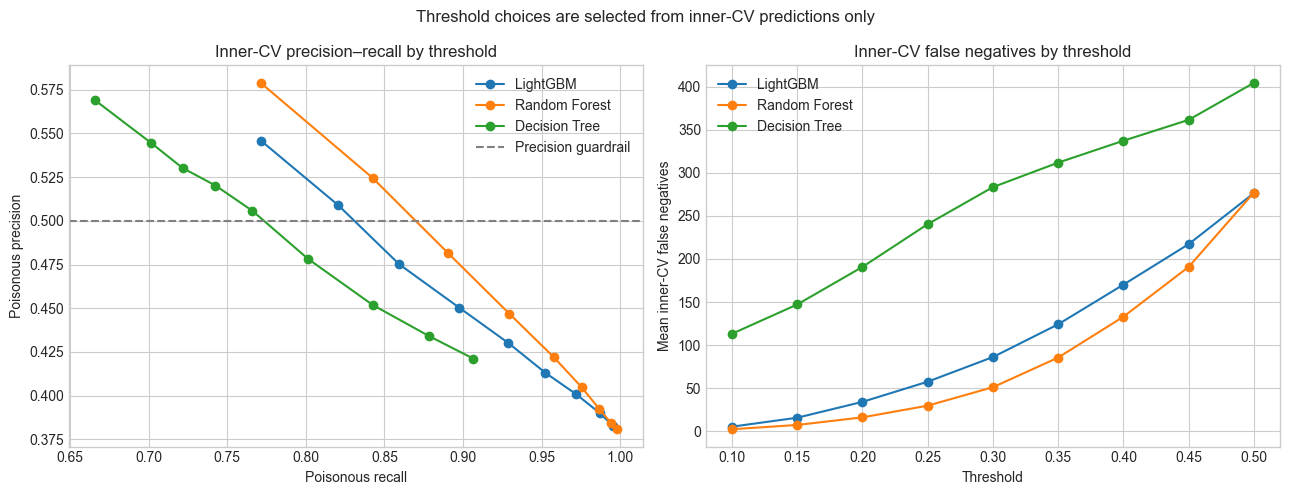

In [7]:
# Review the threshold chosen independently inside each outer fold and its resulting metrics.
# This table is the outer-fold evaluation; the grouped table below summarizes inner threshold sweeps.
selected_thresholds_df = outer_df[
    outer_df['strategy'] == strategy_names[2]
][['model', 'outer_fold', 'threshold', 'threshold_met_inner_guardrails',
   'poisonous_recall', 'false_negatives', 'false_negative_rate',
   'poisonous_precision', 'poisonous_f1', 'balanced_accuracy', 'false_positives']]
display(selected_thresholds_df)
# Count folds meeting guardrails at each candidate threshold, alongside average inner scores.
display(threshold_df.groupby(['model', 'threshold']).agg(
    inner_recall=('inner_recall', 'mean'),
    inner_precision=('inner_precision', 'mean'),
    inner_f1=('inner_f1', 'mean'),
    inner_balanced_accuracy=('inner_balanced_accuracy', 'mean'),
    guardrail_folds=('threshold_met_guardrails', 'sum'),
).reset_index())

# Summarize mean inner-CV precision/recall and false-negative behavior across thresholds.
# Compare inner precision/recall trade-offs and average inner false negatives per threshold.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in pipelines:
    subset = threshold_df[threshold_df['model'] == model_name]
    # Group folds at the same threshold so plotted points show average inner-CV behavior.
    grouped = subset.groupby('threshold').agg(
        recall=('inner_recall', 'mean'), precision=('inner_precision', 'mean'),
        false_negatives=('inner_false_negatives', 'mean'),
    )
    axes[0].plot(grouped['recall'], grouped['precision'], marker='o', label=model_name)
    axes[1].plot(grouped.index, grouped['false_negatives'], marker='o', label=model_name)
axes[0].axhline(MIN_POISONOUS_PRECISION, linestyle='--', color='gray', label='Precision guardrail')
axes[0].set(xlabel='Poisonous recall', ylabel='Poisonous precision', title='Inner-CV precision–recall by threshold')
axes[1].set(xlabel='Threshold', ylabel='Mean inner-CV false negatives', title='Inner-CV false negatives by threshold')
for ax in axes:
    ax.legend()
fig.suptitle('Threshold choices are selected from inner-CV predictions only')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_tuning_inner_threshold_tradeoffs.png', dpi=160)
# Display this inner-CV threshold diagnostic once and close its figure afterward.
plt.show()
plt.close(fig)

## 9. Tuned versus untuned comparison

Report fold means and standard deviations from untouched outer validation folds for the default candidate, tuned candidate at 0.5, and tuned candidate with its inner-selected threshold. Pooled outer-fold false-negative totals are useful counts over all 4,000 OOF observations, not final test counts.

In [8]:
# Aggregate outer-fold metrics with mean/std, then also calculate pooled held-out predictions.
# Per-fold mean/std communicates variability; pooled counts describe errors across all held-out rows.
metric_columns = [
    'accuracy', 'balanced_accuracy', 'poisonous_precision', 'poisonous_recall',
    'poisonous_f1', 'roc_auc', 'false_negatives', 'false_negative_rate', 'false_positives',
]
# Group by algorithm and evaluation strategy so each comparison uses matching outer folds.
outer_summary = outer_df.groupby(['model', 'strategy'])[metric_columns].agg(['mean', 'std'])
display(outer_summary)

# Ensure every training example has exactly one outer-fold prediction before pooling results.
pooled_outer_rows = []
for model_name in pipelines:
    for strategy in strategy_names:
        y_pred = outer_predictions[model_name][strategy]
        probability = outer_probabilities[model_name][strategy]
        if np.any(y_pred < 0) or np.isnan(probability).any():
            raise RuntimeError(f'Missing outer-fold predictions for {model_name}, {strategy}.')
        # Pool each row's single held-out prediction; this is still CV, not final test evaluation.
        metrics = evaluate_at_predictions(y_train, y_pred, probability)
        fold_thresholds = outer_df.loc[
            (outer_df['model'] == model_name) & (outer_df['strategy'] == strategy), 'threshold'
        ].tolist()
        # Store the fold-specific threshold list so threshold variability remains visible.
        pooled_outer_rows.append({
            'model': model_name,
            'strategy': strategy,
            'thresholds_by_outer_fold': json.dumps([float(value) for value in fold_thresholds]),
            **metrics,
        })
pooled_outer_df = pd.DataFrame(pooled_outer_rows)
display(pooled_outer_df[['model', 'strategy', 'thresholds_by_outer_fold',
                         'poisonous_recall', 'false_negatives', 'false_negative_rate',
                         'poisonous_precision', 'poisonous_f1', 'balanced_accuracy',
                         'roc_auc', 'false_positives']])

accuracy           balanced_accuracy  \
                                             mean       std              mean   
model         strategy                                                          
Decision Tree Tuned (inner-CV threshold)  0.64725  0.016355          0.669698   
              Tuned (threshold 0.5)       0.67500  0.037801          0.675505   
              Untuned (threshold 0.5)     0.70500  0.010117          0.683897   
LightGBM      Tuned (inner-CV threshold)  0.64775  0.017928          0.685489   
              Tuned (threshold 0.5)       0.68700  0.037766          0.708962   
              Untuned (threshold 0.5)     0.78400  0.007573          0.746307   
Random Forest Tuned (inner-CV threshold)  0.64475  0.052970          0.688118   
              Tuned (threshold 0.5)       0.69350  0.096394          0.716579   
              Untuned (threshold 0.5)     0.78700  0.015119          0.746909   

                                                   poisonous_precision  \
                                               std                mean   
model         strategy                                                   
Decision Tree Tuned (inner-CV threshold)  0.016195            0.523903   
              Tuned (threshold 0.5)       0.008500            0.578650   
              Untuned (threshold 0.5)     0.011130            0.613392   
LightGBM      Tuned (inner-CV threshold)  0.012450            0.522202   
              Tuned (threshold 0.5)       0.026657            0.564422   
              Untuned (threshold 0.5)     0.011263            0.785310   
Random Forest Tuned (inner-CV threshold)  0.041365            0.521582   
              Tuned (threshold 0.5)       0.066966            0.587733   
              Untuned (threshold 0.5)     0.017935            0.800715   

                                                   poisonous_recall            \
                                               std             mean       std   
model         strategy                                                          
Decision Tree Tuned (inner-CV threshold)  0.016202         0.762180  0.055833   
              Tuned (threshold 0.5)       0.083793         0.677652  0.144771   
              Untuned (threshold 0.5)     0.014006         0.597087  0.020652   
LightGBM      Tuned (inner-CV threshold)  0.015752         0.840819  0.035112   
              Tuned (threshold 0.5)       0.047211         0.799235  0.027052   
              Untuned (threshold 0.5)     0.009879         0.591163  0.028278   
Random Forest Tuned (inner-CV threshold)  0.043144         0.866590  0.014756   
              Tuned (threshold 0.5)       0.103226         0.811735  0.063579   
              Untuned (threshold 0.5)     0.020984         0.581918  0.031281   

                                         poisonous_f1             roc_auc  \
                                                 mean       std      mean   
model         strategy                                                      
Decision Tree Tuned (inner-CV threshold)     0.620144  0.019542  0.743995   
              Tuned (threshold 0.5)          0.608488  0.027994  0.743995   
              Untuned (threshold 0.5)        0.605005  0.014833  0.683897   
LightGBM      Tuned (inner-CV threshold)     0.643765  0.010237  0.799728   
              Tuned (threshold 0.5)          0.660060  0.023852  0.799728   
              Untuned (threshold 0.5)        0.674169  0.017509  0.815523   
Random Forest Tuned (inner-CV threshold)     0.650153  0.031808  0.814359   
              Tuned (threshold 0.5)          0.673393  0.052995  0.814359   
              Untuned (threshold 0.5)        0.673806  0.026720  0.827172   

                                                   false_negatives             \
                                               std            mean        std   
model         strategy                                                          
Decision Tree Tuned (inner-CV threshol

,model,strategy,thresholds_by_outer_fold,poisonous_recall,false_negatives,false_negative_rate,poisonous_precision,poisonous_f1,balanced_accuracy,roc_auc,false_positives
0,LightGBM,Untuned (threshold 0.5),"[0.5, 0.5, 0.5, 0.5, 0.5]",0.591149,619,0.408851,0.785088,0.674454,0.746299,0.814757,245
1,LightGBM,Tuned (threshold 0.5),"[0.5, 0.5, 0.5, 0.5, 0.5]",0.799207,304,0.200793,0.560704,0.659041,0.708936,0.797396,948
2,LightGBM,Tuned (inner-CV threshold),"[0.5, 0.45, 0.5, 0.4, 0.45]",0.840819,241,0.159181,0.521508,0.643742,0.685494,0.797396,1168
3,Random Forest,Untuned (threshold 0.5),"[0.5, 0.5, 0.5, 0.5, 0.5]",0.581902,633,0.418098,0.800909,0.674063,0.746904,0.826520,219
4,Random Forest,Tuned (threshold 0.5),"[0.5, 0.5, 0.5, 0.5, 0.5]",0.811757,285,0.188243,0.566359,0.667210,0.716619,0.809788,941
5,Random Forest,Tuned (inner-CV threshold),"[0.4, 0.5, 0.5, 0.45, 0.4]",0.866579,202,0.133421,0.518372,0.648702,0.688116,0.809788,1219
6,Decision Tree,Untuned (threshold 0.5),"[0.5, 0.5, 0.5, 0.5, 0.5]",0.597094,610,0.402906,0.613297,0.605087,0.683905,0.683905,570
7,Decision Tree,Tuned (threshold 0.5),"[0.5, 0.5, 0.5, 0.5, 0.5]",0.677675,488,0.322325,0.558215,0.612172,0.675523,0.737275,812
8,Decision Tree,Tuned (inner-CV threshold),"[0.4, 0.25, 0.5, 0.5, 0.35]",0.762219,360,0.237781,0.523356,0.620597,0.669726,0.737275,1051


## 10. Confusion matrices from outer-fold predictions

These pooled confusion matrices use only predictions for observations held out from the corresponding outer fit. They are nested-CV diagnostics—not in-sample results and not final test evaluation.

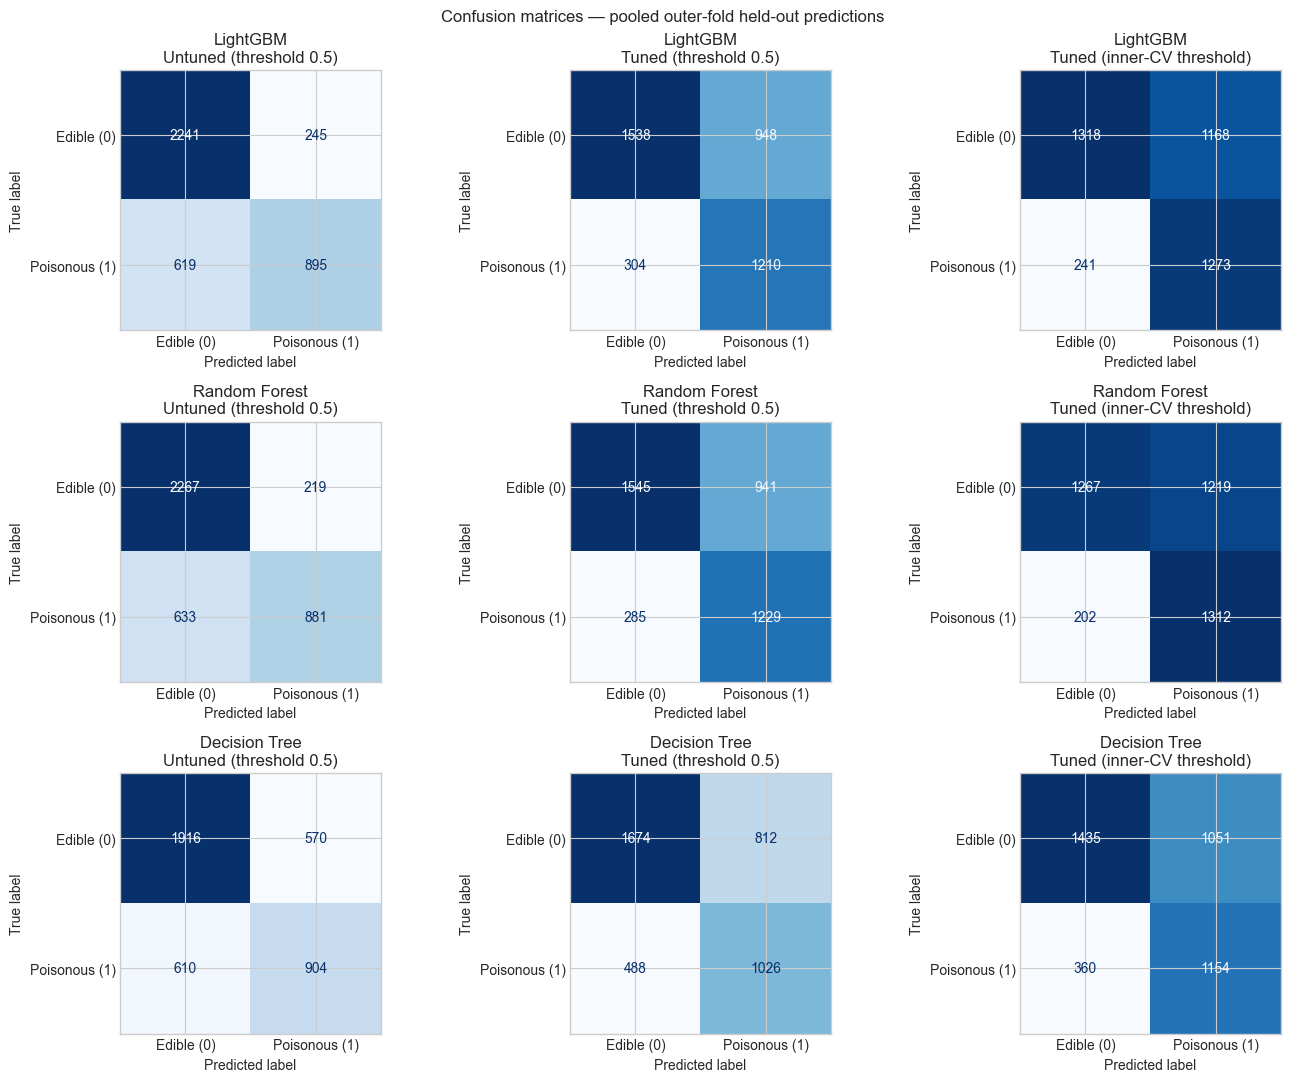

In [9]:
# Compare pooled outer-fold confusion matrices for all models and threshold strategies.
# The axis layout is one row per model and one column per threshold/model strategy.
fig, axes = plt.subplots(len(pipelines), len(strategy_names), figsize=(14, 11))
for row_index, model_name in enumerate(pipelines):
    for column_index, strategy in enumerate(strategy_names):
        # These labels come from outer-held-out predictions, never the fit predictions.
        ConfusionMatrixDisplay.from_predictions(
            y_train,
            outer_predictions[model_name][strategy],
            labels=[0, 1],
            display_labels=['Edible (0)', 'Poisonous (1)'],
            cmap='Blues',
            colorbar=False,
            values_format='d',
            ax=axes[row_index, column_index],
        )
        axes[row_index, column_index].set_title(f'{model_name}\n{strategy}')
fig.suptitle('Confusion matrices — pooled outer-fold held-out predictions')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_tuning_outer_confusion_matrices.png', dpi=160)
# Display once and close the large grid to prevent a second inline rendering.
plt.show()
plt.close(fig)

## 11. ROC and precision–recall analysis

Curves use pooled outer-fold probabilities from each corresponding held-out fold. They show ranking behavior across thresholds and do not determine the per-fold thresholds; those were selected exclusively from inner-fold predictions.

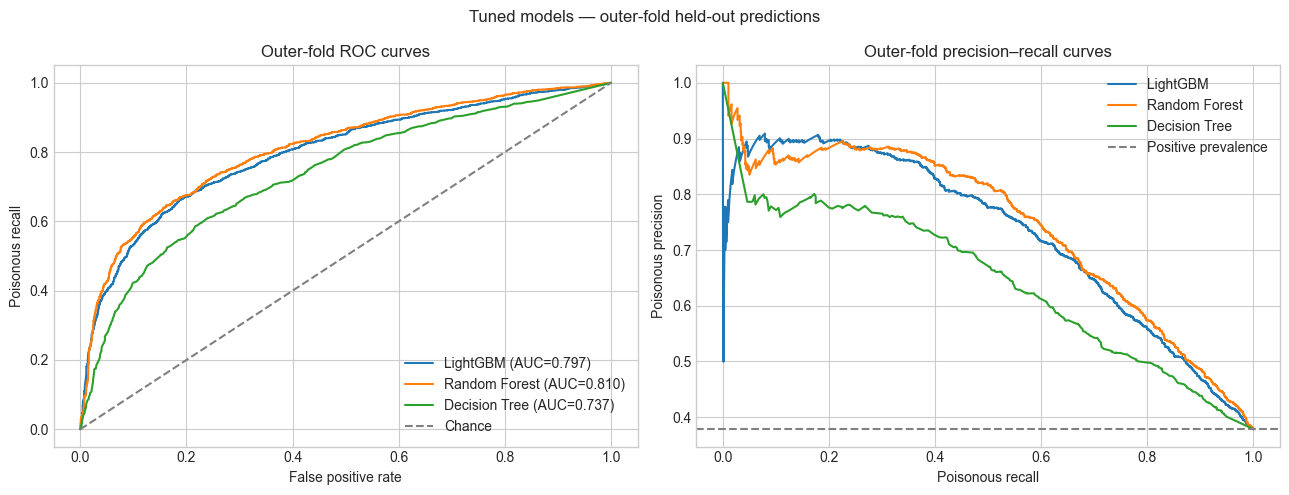

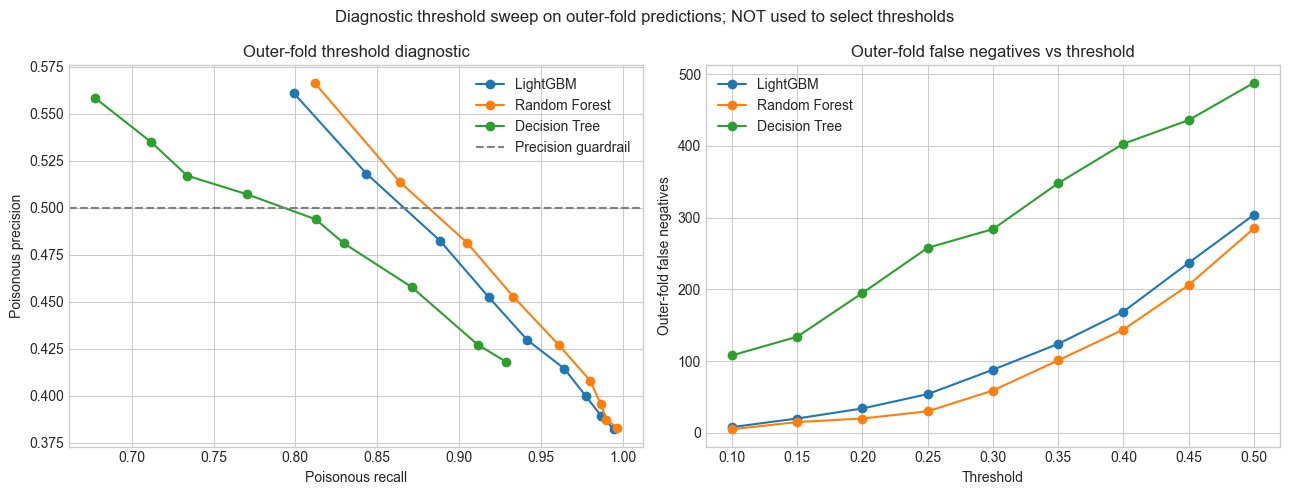

In [10]:
# Plot ROC and precision-recall behavior from outer-fold held-out probabilities.
# Curves show ranking/trade-offs; the chosen probability threshold is not represented by one point.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in pipelines:
    # Use the tuned-threshold strategy's probabilities; thresholding does not alter ROC/PR scores.
    probability = outer_probabilities[model_name][strategy_names[2]]
    fpr, tpr, _ = roc_curve(y_train, probability, pos_label=1)
    axes[0].plot(fpr, tpr, label=f'{model_name} (AUC={roc_auc_score(y_train, probability):.3f})')
    # Precision-recall focuses on the positive class and is compared with its prevalence baseline.
    precision, recall, _ = precision_recall_curve(y_train, probability, pos_label=1)
    axes[1].plot(recall, precision, label=model_name)
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
axes[0].set(xlabel='False positive rate', ylabel='Poisonous recall', title='Outer-fold ROC curves')
axes[1].axhline(y_train.mean(), linestyle='--', color='gray', label='Positive prevalence')
axes[1].set(xlabel='Poisonous recall', ylabel='Poisonous precision', title='Outer-fold precision–recall curves')
for ax in axes:
    ax.legend()
fig.suptitle('Tuned models — outer-fold held-out predictions')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_tuning_outer_roc_pr_curves.png', dpi=160)
# Display ROC/PR charts once and close them before building the next figure.
plt.show()
plt.close(fig)

# This threshold sweep is a diagnostic over outer-fold predictions only; it does not
# select the threshold and must not feed back into the nested-CV selection process.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in pipelines:
    # Use outer-held-out scores for diagnosis only; these values do not choose thresholds.
    probability = threshold_sweep_probabilities[model_name]
    sweep_rows = [
        threshold_metrics(y_train, probability, float(threshold))
        for threshold in THRESHOLDS
    ]
    # Align each computed metric row with the threshold that produced it.
    sweep_df = pd.DataFrame(sweep_rows, index=THRESHOLDS)
    axes[0].plot(sweep_df['poisonous_recall'], sweep_df['poisonous_precision'], marker='o', label=model_name)
    axes[1].plot(THRESHOLDS, sweep_df['false_negatives'], marker='o', label=model_name)
axes[0].axhline(MIN_POISONOUS_PRECISION, linestyle='--', color='gray', label='Precision guardrail')
axes[0].set(xlabel='Poisonous recall', ylabel='Poisonous precision', title='Outer-fold threshold diagnostic')
axes[1].set(xlabel='Threshold', ylabel='Outer-fold false negatives', title='Outer-fold false negatives vs threshold')
for ax in axes:
    ax.legend()
fig.suptitle('Diagnostic threshold sweep on outer-fold predictions; NOT used to select thresholds')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_tuning_outer_threshold_diagnostics.png', dpi=160)
# Display this diagnostic once and close it after saving.
plt.show()
plt.close(fig)

## 12. Overfitting analysis

Compare the selected search candidate's inner training-fold and inner validation-fold means per outer iteration. These gaps indicate overfitting risk but are not a reason to select solely by the smallest gap. Depth, minimum leaf size, regularization, and class weights are visible in the selected parameters for interpretation.

,model,outer_fold,metric,inner_training_mean,inner_validation_mean,train_minus_validation
0,LightGBM,1,poisonous_recall,0.941832,0.791254,0.150578
1,LightGBM,1,balanced_accuracy,0.810453,0.671788,0.138665
2,LightGBM,1,roc_auc,0.923766,0.763165,0.160602
3,Random Forest,1,poisonous_recall,0.971122,0.712871,0.258251
4,Random Forest,1,balanced_accuracy,0.934502,0.724903,0.209600
5,Random Forest,1,roc_auc,0.982273,0.793409,0.188864
6,Decision Tree,1,poisonous_recall,0.794554,0.634488,0.160066
7,Decision Tree,1,balanced_accuracy,0.795916,0.666100,0.129817
8,Decision Tree,1,roc_auc,0.889960,0.712007,0.177953
9,LightGBM,2,poisonous_recall,0.944260,0.777068,0.167192


inner_training_mean  inner_validation_mean  \
model         metric                                                          
Decision Tree balanced_accuracy             0.791874               0.671254   
              poisonous_recall              0.819767               0.666113   
              roc_auc                       0.880419               0.723878   
LightGBM      balanced_accuracy             0.834934               0.688289   
              poisonous_recall              0.931388               0.771795   
              roc_auc                       0.933360               0.772932   
Random Forest balanced_accuracy             0.880981               0.706962   
              poisonous_recall              0.973084               0.771313   
              roc_auc                       0.966760               0.792765   

                                 train_minus_validation  
model         metric                                     
Decision Tree balanced_accuracy                0.120620  
              poisonous_recall                 0.153654  
              roc_auc                          0.156540  
LightGBM      balanced_accuracy                0.146645  
              poisonous_recall                 0.159593  
              roc_auc                          0.160427  
Random Forest balanced_accuracy                0.174019  
              poisonous_recall                 0.201771  
              roc_auc                          0.173995

Direct outer-train in-sample versus held-out-fold gaps (training scores are not generalization estimates):


outer_training_score_in_sample  \
model         strategy                   metric                                              
Decision Tree Tuned (inner-CV threshold) balanced_accuracy                        0.764236   
                                         poisonous_recall                         0.879629   
                                         roc_auc                                  0.867457   
              Tuned (threshold 0.5)      balanced_accuracy                        0.770447   
                                         poisonous_recall                         0.797725   
                                         roc_auc                                  0.867457   
              Untuned (threshold 0.5)    balanced_accuracy                        1.000000   
                                         poisonous_recall                         1.000000   
                                         roc_auc                                  1.000000   
LightGBM      Tuned (inner-CV threshold) balanced_accuracy                        0.798968   
                                         poisonous_recall                         0.949805   
                                         roc_auc                                  0.921972   
              Tuned (threshold 0.5)      balanced_accuracy                        0.822024   
                                         poisonous_recall                         0.913967   
                                         roc_auc                                  0.921972   
              Untuned (threshold 0.5)    balanced_accuracy                        0.876470   
                                         poisonous_recall                         0.784015   
                                         roc_auc                                  0.970347   
Random Forest Tuned (inner-CV threshold) balanced_accuracy                        0.818892   
                                         poisonous_recall                         0.986128   
                                         roc_auc                                  0.955520   
              Tuned (threshold 0.5)      balanced_accuracy                        0.849372   
                                         poisonous_recall                         0.972260   
                                         roc_auc                                  0.955520   
              Untuned (threshold 0.5)    balanced_accuracy                        1.000000   
                                         poisonous_recall                         1.000000   
                                         roc_auc                                  1.000000   

                                                            outer_validation_score  \
model         strategy                   metric                                      
Decision Tree Tuned (inner-CV threshold) balanced_accuracy                0.669698   
                                         poisonous_recall                 0.762180   
                                         roc_auc                          0.743995   
              Tuned (threshold 0.5)      balanced_accuracy                0.675505   
                                         poisonous_recall                 0.677652   
                                         roc_auc                          0.743995   
              Untuned (threshold 0.5)    balanced_accuracy                0.683897   
                                         poisonous_recall                 0.597087   
                                         roc_auc                          0.683897   
LightGBM      Tuned (inner-CV threshold) balanced_accuracy                0.685489   
                                         poisonous_recall                 0.840819   
                                         roc_auc                          0.799728   
              Tuned (threshold 0.5)      balanced_accuracy                0.708962   
                                         po

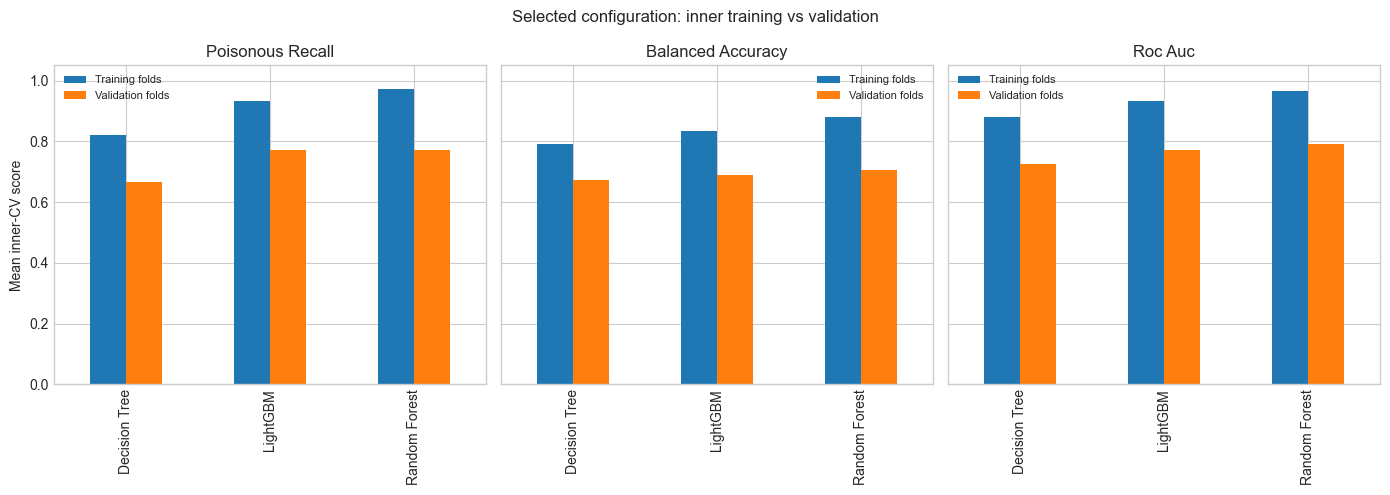

Large positive train-validation gaps are signs of overfitting risk; smaller gaps alone do not establish a better model.


In [11]:
# Compare selected inner-search training/validation scores and outer-fold fit gaps.
# Gaps are warning signs only; in-sample training metrics are not generalization estimates.
# Reshape the selected configuration scores into one row per model/fold/metric.
overfit_rows = []
for _, row in search_df.iterrows():
    for metric, validation_key, train_key in [
        ('poisonous_recall', 'best_inner_recall', 'inner_train_recall'),
        ('balanced_accuracy', 'best_inner_balanced_accuracy', 'inner_train_balanced_accuracy'),
        ('roc_auc', 'best_inner_roc_auc', 'inner_train_roc_auc'),
    ]:
        # Keep both raw means and their difference so the size of each gap can be inspected.
        overfit_rows.append({
            'model': row['model'],
            'outer_fold': int(row['outer_fold']),
            'metric': metric,
            'inner_training_mean': row[train_key],
            'inner_validation_mean': row[validation_key],
            'train_minus_validation': row[train_key] - row[validation_key],
        })
overfit_df = pd.DataFrame(overfit_rows)
display(overfit_df)
# Average the per-outer-fold inner training/validation means for a compact summary table.
overfit_summary = overfit_df.groupby(['model', 'metric'])[
    ['inner_training_mean', 'inner_validation_mean', 'train_minus_validation']
].mean()
display(overfit_summary)

# Separate fit-gap table covers the outer-training fit compared with its held-out fold.
outer_fit_gap_df = pd.DataFrame(outer_fit_gap_records)
outer_fit_gap_summary = outer_fit_gap_df.groupby(['model', 'strategy', 'metric'])[
    ['outer_training_score_in_sample', 'outer_validation_score', 'train_minus_validation']
].mean()
print('Direct outer-train in-sample versus held-out-fold gaps (training scores are not generalization estimates):')
display(outer_fit_gap_summary)

# Shared y-axis makes train/validation gaps visually comparable across the three metrics.
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for ax, metric in zip(axes, ['poisonous_recall', 'balanced_accuracy', 'roc_auc']):
    subset = overfit_summary.xs(metric, level='metric')
    subset[['inner_training_mean', 'inner_validation_mean']].plot(kind='bar', ax=ax, ylim=(0, 1.05))
    ax.set_title(metric.replace('_', ' ').title())
    ax.set_ylabel('Mean inner-CV score')
    ax.set_xlabel('')
    ax.legend(['Training folds', 'Validation folds'], fontsize=8)
fig.suptitle('Selected configuration: inner training vs validation')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'mushroom_tuning_overfitting.png', dpi=160)
# Display the diagnostic plot once and close the figure to prevent duplicate output.
plt.show()
plt.close(fig)
print('Large positive train-validation gaps are signs of overfitting risk; smaller gaps alone do not establish a better model.')

## 13. Final candidate selection

Use the pooled outer-fold metrics for the tuned-threshold strategy, with no relaxed constraints: balanced accuracy must be at least 0.65 and poisonous precision at least 0.50. Among feasible model families, maximize outer-fold poisonous recall; then prefer fewer outer-fold false negatives, precision, balanced accuracy, recall stability, and simpler models. If none pass both constraints, explicitly report that no candidate meets the selection rule.

In [12]:
# Apply the documented constraints before ranking candidates by recall and false negatives.
# Only the tuned-inner-threshold strategy is eligible for this safety/utility comparison.
tuned_threshold_summary = pooled_outer_df[
    pooled_outer_df['strategy'] == strategy_names[2]
].copy()
# Add fold-to-fold recall variation to avoid ignoring instability in pooled performance.
tuned_threshold_summary['recall_std_across_outer_folds'] = tuned_threshold_summary['model'].map(
    outer_df[outer_df['strategy'] == strategy_names[2]]
    .groupby('model')['poisonous_recall'].std()
)
# Use a simple, explicit complexity preference only as a late tie-breaker.
tuned_threshold_summary['complexity_order'] = tuned_threshold_summary['model'].map({
    'Decision Tree': 0, 'LightGBM': 1, 'Random Forest': 2,
})
tuned_threshold_summary['meets_selection_constraints'] = (
    (tuned_threshold_summary['balanced_accuracy'] >= MIN_BALANCED_ACCURACY)
    & (tuned_threshold_summary['poisonous_precision'] >= MIN_POISONOUS_PRECISION)
)
display(tuned_threshold_summary[[
    'model', 'thresholds_by_outer_fold', 'poisonous_recall', 'false_negatives',
    'false_negative_rate', 'poisonous_precision', 'poisonous_f1',
    'balanced_accuracy', 'roc_auc', 'recall_std_across_outer_folds',
    'meets_selection_constraints',
]])
# Do not relax constraints automatically if none of the candidates are eligible.
eligible_models = tuned_threshold_summary[tuned_threshold_summary['meets_selection_constraints']]
if eligible_models.empty:
    selected_model_name = None
    print(
        'No model met both exploratory outer-CV guardrails. No candidate is selected; '
        'do not silently relax the thresholds or constraints.'
    )
else:
    # Rank eligible candidates by recall, then fewer FNs, then precision/balance/stability/complexity.
    selected_model_name = eligible_models.sort_values(
        ['poisonous_recall', 'false_negatives', 'poisonous_precision',
         'balanced_accuracy', 'recall_std_across_outer_folds', 'complexity_order'],
        ascending=[False, True, False, False, True, True],
    ).iloc[0]['model']
    selected_outer = tuned_threshold_summary.loc[
        tuned_threshold_summary['model'] == selected_model_name
    ].iloc[0]
    print(f'Selected candidate for final test evaluation in notebook 07: {selected_model_name}.')
    print(
        f'Nested outer-CV pooled metrics: recall={selected_outer.poisonous_recall:.4f}, '
        f'FN={int(selected_outer.false_negatives)}, FNR={selected_outer.false_negative_rate:.4f}, '
        f'precision={selected_outer.poisonous_precision:.4f}, F1={selected_outer.poisonous_f1:.4f}, '
        f'balanced accuracy={selected_outer.balanced_accuracy:.4f}, ROC-AUC={selected_outer.roc_auc:.4f}.'
    )
print('Outer-fold model-family selection is itself exploratory; confirm the chosen candidate once on the untouched test set in notebook 07.')

,model,thresholds_by_outer_fold,poisonous_recall,false_negatives,false_negative_rate,poisonous_precision,poisonous_f1,balanced_accuracy,roc_auc,recall_std_across_outer_folds,meets_selection_constraints
2,LightGBM,"[0.5, 0.45, 0.5, 0.4, 0.45]",0.840819,241,0.159181,0.521508,0.643742,0.685494,0.797396,0.035112,True
5,Random Forest,"[0.4, 0.5, 0.5, 0.45, 0.4]",0.866579,202,0.133421,0.518372,0.648702,0.688116,0.809788,0.014756,True
8,Decision Tree,"[0.4, 0.25, 0.5, 0.5, 0.35]",0.762219,360,0.237781,0.523356,0.620597,0.669726,0.737275,0.055833,True


Selected candidate for final test evaluation in notebook 07: Random Forest.
Nested outer-CV pooled metrics: recall=0.8666, FN=202, FNR=0.1334, precision=0.5184, F1=0.6487, balanced accuracy=0.6881, ROC-AUC=0.8098.
Outer-fold model-family selection is itself exploratory; confirm the chosen candidate once on the untouched test set in notebook 07.


## 14. Refit selected candidate on all training data

Repeat inner-CV randomized search for the selected model on all 4,000 training observations, select the threshold from inner out-of-fold predictions, then fit the complete pipeline on all training rows. These full-training CV choices are for the candidate artifact; their inner scores are not a fresh unbiased performance estimate. Notebook 07 is reserved for untouched test evaluation.

In [13]:
# Refit only after nested outer-CV selection is complete; this final tuning uses all
# training rows and inner CV only. The held-out test set remains untouched.
# Defaults stay None when selection fails, preventing a success-shaped fallback artifact.
final_search = None
final_threshold = None
final_pipeline = None
final_threshold_table = None
final_search_feasible_count = None
final_threshold_feasible = None
final_best_params = None
if selected_model_name is not None:
    # Reserve a deterministic inner-fold scheme for parameter selection on all training rows.
    final_cv = StratifiedKFold(
        n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE + 100
    )
    final_folds = list(final_cv.split(X_train, y_train))
    # Repeat the search for the selected model family, now using every training observation.
    final_search = RandomizedSearchCV(
        estimator=pipelines[selected_model_name],
        param_distributions=parameter_distributions[selected_model_name],
        n_iter=N_ITER,
        scoring=SCORING,
        refit=select_search_candidate,
        cv=final_folds,
        random_state=RANDOM_STATE + 100,
        n_jobs=1,
        return_train_score=True,
        error_score='raise',
        verbose=0,
    )
    final_started = time.perf_counter()
    final_search.fit(X_train, y_train)
    final_search_seconds = time.perf_counter() - final_started
    # Save the selected parameters in native JSON-compatible form for metadata/reporting.
    final_best_params = json_safe(final_search.best_params_)
    final_search_feasible_count = int(np.sum(
        (np.asarray(final_search.cv_results_['mean_test_balanced_accuracy']) >= MIN_BALANCED_ACCURACY)
        & (np.asarray(final_search.cv_results_['mean_test_poisonous_precision']) >= MIN_POISONOUS_PRECISION)
    ))
    # Produce full-training inner OOF scores to choose the final deployment threshold.
    final_inner_probability = cross_val_predict(
        clone(final_search.best_estimator_),
        X_train,
        y_train,
        cv=final_folds,
        method='predict_proba',
        n_jobs=1,
    )[:, 1]
    # Select the final operating threshold exclusively from training-only inner OOF probabilities.
    final_threshold_row, final_threshold_table, final_threshold_feasible = choose_threshold(
        y_train, final_inner_probability
    )
    final_threshold = float(final_threshold_row['threshold'])
    if final_search_feasible_count == 0:
        print('NOTE: no full-training inner-search parameter candidate met both search guardrails.')
    if not final_threshold_feasible:
        print('NOTE: no full-training inner-CV threshold met both threshold guardrails; saved threshold is a flagged fallback.')
    # Refit the selected pipeline on all training rows after hyperparameters/threshold are chosen.
    final_pipeline = clone(final_search.best_estimator_).fit(X_train, y_train)
    print(f'Final candidate algorithm: {selected_model_name}')
    print(f'Final training-only selected parameters: {json.dumps(final_best_params, sort_keys=True)}')
    print(f'Final training-only selected threshold: {final_threshold:.2f}')
    print(f'Final search runtime: {final_search_seconds:.1f}s')
else:
    print('No model met the selection rule; no tuned candidate will be refitted or saved.')

Final candidate algorithm: Random Forest
Final training-only selected parameters: {"classifier__class_weight": {"0": 1, "1": 3}, "classifier__max_depth": 20, "classifier__max_features": "sqrt", "classifier__min_samples_leaf": 4, "classifier__min_samples_split": 2, "classifier__n_estimators": 250}
Final training-only selected threshold: 0.50
Final search runtime: 137.6s


## 15. Save models, results, and metadata

Save nested outer-fold scores, threshold/search diagnostics, plots, and—only when a model meets the constraints—the complete preprocessing-plus-estimator candidate together with the threshold and selection metadata. Nothing is deployed or evaluated on the test set here.

In [14]:
# Outer-CV means and standard deviations, plus pooled outer-fold counts.
# First create one export row for every model and evaluation strategy.
outer_metric_rows = []
for (model_name, strategy), group in outer_df.groupby(['model', 'strategy'], sort=False):
    row = {'model': model_name, 'strategy': strategy, 'outer_folds': len(group)}
    # Keep mean/std per-fold scores distinct from the pooled confusion-derived metrics.
    for metric in metric_columns:
        row[f'{metric}_mean'] = float(group[metric].mean())
        row[f'{metric}_std'] = float(group[metric].std(ddof=1))
    # Join the matching pooled record so actual total error counts are included in the export.
    pooled = pooled_outer_df[
        (pooled_outer_df['model'] == model_name)
        & (pooled_outer_df['strategy'] == strategy)
    ].iloc[0]
    for metric in ['false_negatives', 'false_negative_rate', 'false_positives',
                   'poisonous_precision', 'poisonous_recall', 'poisonous_f1',
                   'balanced_accuracy', 'roc_auc']:
        row[f'pooled_outer_{metric}'] = float(pooled[metric])
    row['thresholds_by_outer_fold'] = pooled['thresholds_by_outer_fold']
    outer_metric_rows.append(row)
# Save top-level, detailed-fold, threshold, and overfitting results as separate files.
outer_results_df = pd.DataFrame(outer_metric_rows)
outer_results_df.to_csv(DATA_DIR / 'mushroom_tuning_results.csv', index=False)
# Detail files preserve the evidence behind each aggregate table and plot.
outer_df.to_csv(DATA_DIR / 'mushroom_tuning_outer_fold_details.csv', index=False)
threshold_df.to_csv(DATA_DIR / 'mushroom_tuning_threshold_details.csv', index=False)
overfit_df.to_csv(DATA_DIR / 'mushroom_tuning_overfitting_details.csv', index=False)
outer_fit_gap_df.to_csv(DATA_DIR / 'mushroom_tuning_outer_fit_gaps.csv', index=False)

# Save a clearly labeled candidate bundle (pipeline plus threshold), not a production model.
# Save a bundle only when a candidate satisfied the explicit selection rule.
candidate_path = MODEL_DIR / 'tuned_mushroom_candidate.joblib'
if final_pipeline is not None:
    # Bundle threshold semantics with the fitted pipeline so callers can reproduce decisions.
    candidate_bundle = {
        'pipeline': final_pipeline,
        'threshold': final_threshold,
        'positive_label': POSITIVE_LABEL,
        'positive_label_name': 'poisonous',
        'selected_model': selected_model_name,
        'selection_rule': (
            f'Nested CV: maximize poisonous recall among candidates with '
            f'pooled outer-fold balanced accuracy >= {MIN_BALANCED_ACCURACY:.2f} '
            f'and poisonous precision >= {MIN_POISONOUS_PRECISION:.2f}. '
            'Threshold selected only from inner OOF predictions.'
        ),
        'note': 'Untested tuned candidate; not a final production model.',
    }
    dump(candidate_bundle, candidate_path)
    print(f'Saved complete pipeline and threshold bundle: {candidate_path.relative_to(PROJECT_ROOT)}')

# Keep the experiment setup, objective, model metrics, and limitations auditable as JSON.
# Record experiment parameters, model results, selection criteria, and safety limitations.
summary = {
    'dataset': {
        'training_rows': int(len(X_train)),
        'feature_count': int(X_train.shape[1]),
        'target': 'class',
        'target_mapping': {'0': 'edible', '1': 'poisonous'},
        'class_counts': {str(key): int(value) for key, value in y_train.value_counts().sort_index().items()},
        'test_set_loaded': False,
    },
    'versions': {'scikit_learn': sklearn_version, 'lightgbm': lightgbm_version},
    'cross_validation': {
        'outer': {'strategy': 'StratifiedKFold', 'n_splits': OUTER_SPLITS, 'shuffle': True, 'random_state': RANDOM_STATE},
        'inner': {'strategy': 'StratifiedKFold', 'n_splits': INNER_SPLITS, 'shuffle': True, 'random_state': '42 + outer fold number; final refit seed 142'},
        'outer_folds_shared_by_models': True,
        'pipeline_preprocessing_is_fold_local': True,
        'randomized_search_iterations_per_model_per_outer_fold': N_ITER,
        'search_scoring': list(SCORING),
        'thresholds_investigated': THRESHOLDS.tolist(),
        'threshold_predictions_use_strict_greater_than': True,
    },
    'selection_rule': {
        'minimum_pooled_outer_balanced_accuracy': MIN_BALANCED_ACCURACY,
        'minimum_pooled_outer_poisonous_precision': MIN_POISONOUS_PRECISION,
        'priority': ['poisonous recall', 'fewer pooled outer-fold false negatives', 'poisonous precision', 'balanced accuracy', 'recall stability', 'simplicity'],
        'no_silent_constraint_relaxation': True,
        'selected_model': selected_model_name,
    },
    'nested_evaluation': {
        'runtime_seconds': float(nested_runtime_seconds),
        'outer_fold_results': json_safe(outer_results_df.to_dict(orient='records')),
        'outer_training_vs_validation_gaps': json_safe(outer_fit_gap_summary.reset_index().to_dict(orient='records')),
        'per_fold_search_seconds': {name: [float(value) for value in times] for name, times in search_runtimes.items()},
    },
    'final_training_only_refit': None if final_pipeline is None else {
        'model': selected_model_name,
        'best_params': final_best_params,
        'threshold': final_threshold,
        'search_guardrail_feasible_configurations': final_search_feasible_count,
        'threshold_met_guardrails': bool(final_threshold_feasible),
        'search_seconds': float(final_search_seconds),
        'candidate_bundle': str(candidate_path.relative_to(PROJECT_ROOT)),
        'note': 'Inner-CV selected candidate for notebook 07; no test-set evaluation or deployment.',
    },
    'limitations': [
        'Outer-fold performance is nested CV on the 4,000-row training partition, not final test performance.',
        'Model-family selection across three candidates is exploratory and should be confirmed once on the untouched test set.',
        'Guardrails are exploratory thresholds, not scientifically validated safety criteria.',
        'The saved model is not a real-world mushroom identification or safety system.',
    ],
}
# Persist a machine-readable run summary for notebook 07 and project reporting.
with (DATA_DIR / 'mushroom_tuning_summary.json').open('w', encoding='utf-8') as file:
    json.dump(summary, file, indent=2, allow_nan=False)
print('Saved nested-CV results and summary JSON.')

Saved complete pipeline and threshold bundle: mushroom/data/models/tuned_mushroom_candidate.joblib
Saved nested-CV results and summary JSON.


## 16. Conclusions and next steps

Nested outer-fold results estimate how the search-and-threshold-selection procedure performs on held-out training folds. Inner scores only guide choices and must not be described as unbiased evaluation. The eventual candidate remains untested on the held-out test split until notebook 07.

Prioritize poisonous false negatives while checking the precision and balanced-accuracy guardrails. Thresholds are training-fold-specific during nested evaluation; the saved all-training candidate carries its selected threshold. A high recall score does not establish that a model is safe, and this educational model must not be used to decide whether real mushrooms are edible.

In [15]:
# Print the outer-fold aggregate table and pooled error counts for the presentation summary.
print('Nested outer-CV results by model and strategy:')
# Limit the display to the primary metrics while the CSV retains all detailed columns.
display(outer_results_df[[
    'model', 'strategy', 'poisonous_recall_mean', 'poisonous_recall_std',
    'pooled_outer_false_negatives', 'pooled_outer_false_negative_rate',
    'pooled_outer_poisonous_precision', 'pooled_outer_balanced_accuracy',
    'pooled_outer_roc_auc', 'thresholds_by_outer_fold',
]])
if selected_model_name is None:
    print('Conclusion: no model met both selection constraints; no candidate was saved.')
else:
    print(
        f'Candidate carried forward to notebook 07: {selected_model_name}, '
        f'threshold={final_threshold:.2f}, full-training CV search params={json.dumps(final_best_params, sort_keys=True)}.'
    )
print(f'Nested-CV runtime: {nested_runtime_seconds / 60:.1f} minutes.')
print('Only outer-fold validation scores are used as the nested performance estimate; test data has not been loaded.')

Nested outer-CV results by model and strategy:


,model,strategy,poisonous_recall_mean,poisonous_recall_std,pooled_outer_false_negatives,pooled_outer_false_negative_rate,pooled_outer_poisonous_precision,pooled_outer_balanced_accuracy,pooled_outer_roc_auc,thresholds_by_outer_fold
0,LightGBM,Untuned (threshold 0.5),0.591163,0.028278,619.0,0.408851,0.785088,0.746299,0.814757,"[0.5, 0.5, 0.5, 0.5, 0.5]"
1,LightGBM,Tuned (threshold 0.5),0.799235,0.027052,304.0,0.200793,0.560704,0.708936,0.797396,"[0.5, 0.5, 0.5, 0.5, 0.5]"
2,LightGBM,Tuned (inner-CV threshold),0.840819,0.035112,241.0,0.159181,0.521508,0.685494,0.797396,"[0.5, 0.45, 0.5, 0.4, 0.45]"
3,Random Forest,Untuned (threshold 0.5),0.581918,0.031281,633.0,0.418098,0.800909,0.746904,0.826520,"[0.5, 0.5, 0.5, 0.5, 0.5]"
4,Random Forest,Tuned (threshold 0.5),0.811735,0.063579,285.0,0.188243,0.566359,0.716619,0.809788,"[0.5, 0.5, 0.5, 0.5, 0.5]"
5,Random Forest,Tuned (inner-CV threshold),0.866590,0.014756,202.0,0.133421,0.518372,0.688116,0.809788,"[0.4, 0.5, 0.5, 0.45, 0.4]"
6,Decision Tree,Untuned (threshold 0.5),0.597087,0.020652,610.0,0.402906,0.613297,0.683905,0.683905,"[0.5, 0.5, 0.5, 0.5, 0.5]"
7,Decision Tree,Tuned (threshold 0.5),0.677652,0.144771,488.0,0.322325,0.558215,0.675523,0.737275,"[0.5, 0.5, 0.5, 0.5, 0.5]"
8,Decision Tree,Tuned (inner-CV threshold),0.762180,0.055833,360.0,0.237781,0.523356,0.669726,0.737275,"[0.4, 0.25, 0.5, 0.5, 0.35]"


Candidate carried forward to notebook 07: Random Forest, threshold=0.50, full-training CV search params={"classifier__class_weight": {"0": 1, "1": 3}, "classifier__max_depth": 20, "classifier__max_features": "sqrt", "classifier__min_samples_leaf": 4, "classifier__min_samples_split": 2, "classifier__n_estimators": 250}.
Nested-CV runtime: 8.9 minutes.
Only outer-fold validation scores are used as the nested performance estimate; test data has not been loaded.
